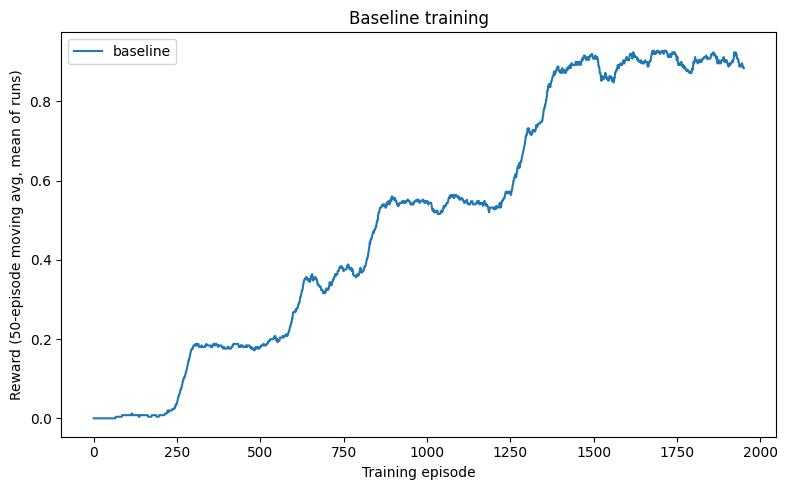

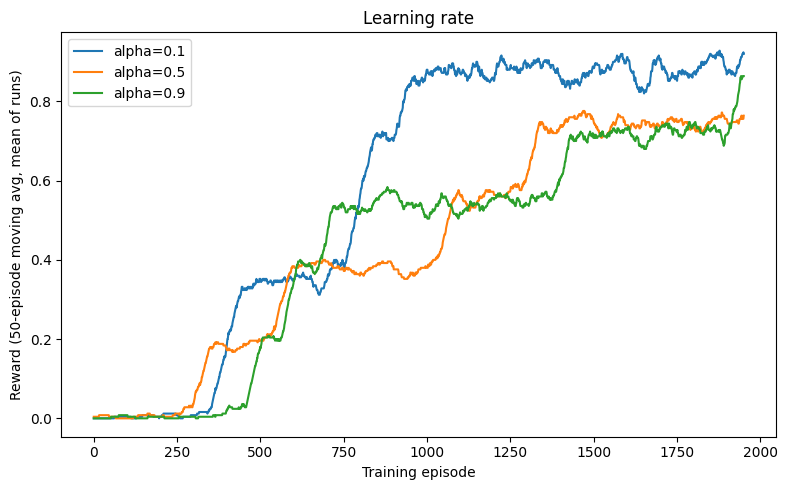

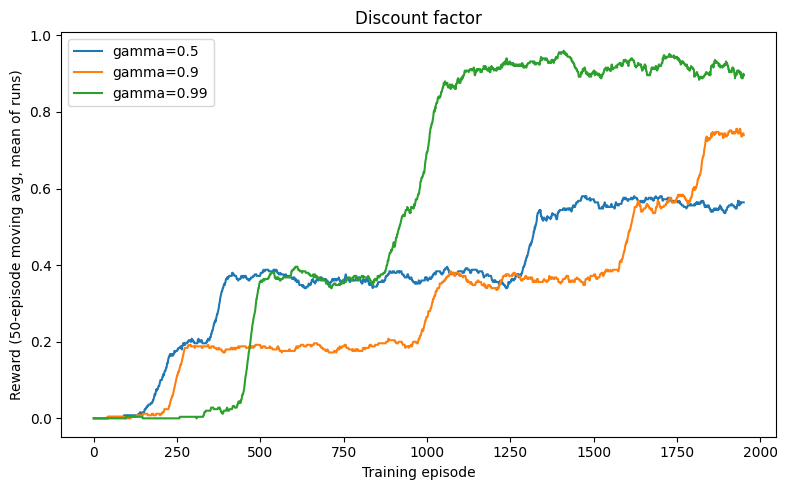

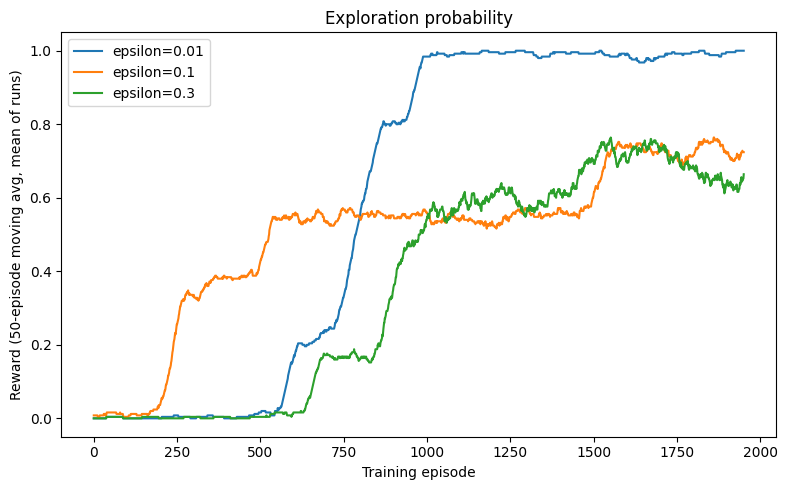

Best config: {'alpha': 0.5, 'gamma': 0.9, 'epsilon': 0.01, 'episodes': 2000, 'noise': 0.0}
Baseline eval: {'mean_reward': np.float64(1.0), 'success_rate': np.float64(1.0), 'mean_steps_on_success': np.float64(14.0)}
Best eval:     {'mean_reward': np.float64(1.0), 'success_rate': np.float64(1.0), 'mean_steps_on_success': np.float64(14.0)}


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Trained and evaluated at p=0.0: {'mean_reward': np.float64(1.0), 'success_rate': np.float64(1.0), 'mean_steps_on_success': np.float64(14.0)}


Trained and evaluated at p=0.1: {'mean_reward': np.float64(0.87), 'success_rate': np.float64(0.87), 'mean_steps_on_success': np.float64(16.2183908045977)}


Trained and evaluated at p=0.25: {'mean_reward': np.float64(0.73), 'success_rate': np.float64(0.73), 'mean_steps_on_success': np.float64(21.52054794520548)}


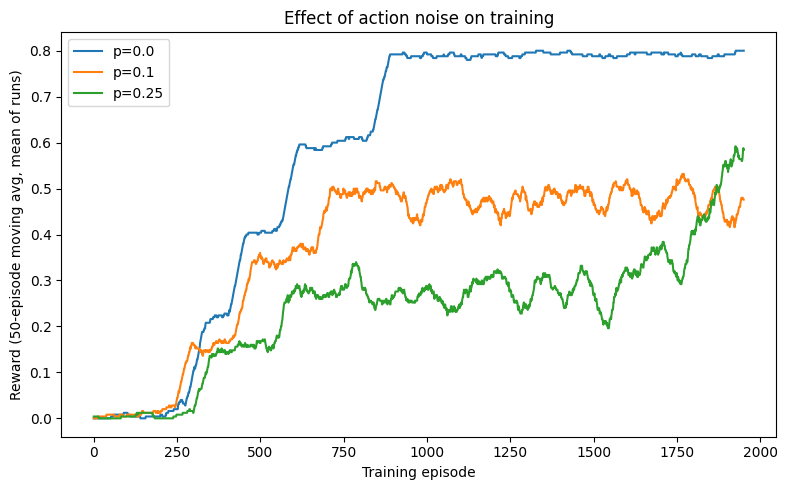

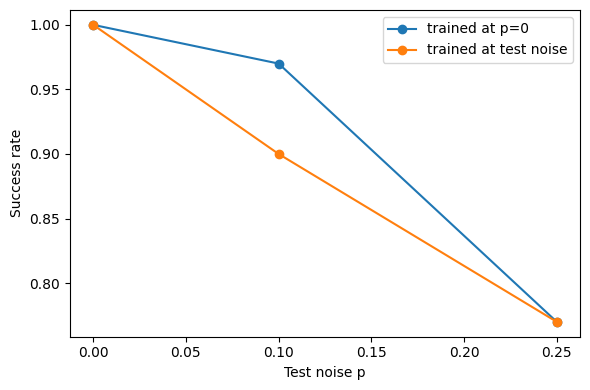

In [1]:
import os

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Video, display
from tqdm import tqdm

rng = np.random.default_rng(123)
os.makedirs("results", exist_ok=True)

################### Settings ###########################

# Settings that stay fixed unless an experiment varies them
N_RUNS = 5  # Runs per configuration, to account for stochasticity
BASELINE = dict(
    alpha=0.5,  # Learning rate
    gamma=0.9,  # Discounting rate
    epsilon=0.1,  # Exploration probability
    episodes=2000,
    noise=0.0,  # Probability that the intended action is replaced
)

#######################################################

all_runs = []  # (config, rewards, qtable) for every non-noisy training run


def make_env(render_mode=None):
    """8x8 FrozenLake, deterministic."""
    return gym.make(
        "FrozenLake-v1", map_name="8x8", is_slippery=False, render_mode=render_mode
    )


def noisy_step(env, action, noise):
    """With probability `noise`, replace the intended action with a different valid action."""
    if rng.uniform(0, 1) < noise:
        action = rng.choice([a for a in range(env.action_space.n) if a != action])
    return env.step(action)


def choose_action(qtable, state, epsilon, n_actions):
    """Epsilon-greedy action selection."""
    # Exploration
    if rng.uniform(0, 1) < epsilon:
        return int(rng.integers(n_actions))

    # Exploitation (taking the biggest Q-value for this state)
    # Break ties randomly
    max_ids = np.where(qtable[state, :] == np.max(qtable[state, :]))[0]
    return int(rng.choice(max_ids))


def train(alpha, gamma, epsilon, episodes, noise=0.0, n_runs=N_RUNS):
    """Tabular Q-learning. Returns rewards (episodes x runs) and the run-averaged Q-table."""
    env = make_env()
    n_states, n_actions = env.observation_space.n, env.action_space.n
    rewards = np.zeros((episodes, n_runs))
    qtables = np.zeros((n_runs, n_states, n_actions))

    for run in range(n_runs):
        qtable = np.zeros((n_states, n_actions))  # Q-value initialization

        for episode in tqdm(range(episodes), desc=f"Run {run}/{n_runs}", leave=False):
            state, info = env.reset()
            done = False

            while not done:
                action = choose_action(qtable, state, epsilon, n_actions)

                # Take the action (a) and observe the outcome state(s') and reward (r)
                new_state, reward, terminated, truncated, info = noisy_step(
                    env, action, noise
                )
                done = terminated or truncated

                # Q(s,a) := Q(s,a) + alpha * [r + gamma * max Q(s',a') - Q(s,a)]
                # Terminal states have no future value, so only bootstrap if not terminated
                target = reward if terminated else reward + gamma * np.max(qtable[new_state, :])
                qtable[state, action] += alpha * (target - qtable[state, action])

                rewards[episode, run] += reward
                state = new_state

        qtables[run] = qtable

    env.close()
    return rewards, qtables.mean(axis=0)  # Average the Q-table between runs


def evaluate(qtable, n_episodes=30, noise=0.0):
    """Run the greedy policy (exploration disabled) and report mean reward, success rate, steps."""
    env = make_env()
    totals, steps = [], []

    for _ in range(n_episodes):
        state, info = env.reset()
        done = False
        total, n = 0, 0

        while not done:
            action = int(np.argmax(qtable[state, :]))  # Always take the best known action
            state, reward, terminated, truncated, info = noisy_step(env, action, noise)
            done = terminated or truncated
            total += reward
            n += 1

        totals.append(total)
        steps.append(n)

    env.close()
    totals, steps = np.array(totals), np.array(steps)
    success = totals > 0
    return dict(
        mean_reward=totals.mean(),
        success_rate=success.mean(),
        mean_steps_on_success=steps[success].mean() if success.any() else np.nan,
    )


def smooth(x, w=50):
    """Moving average so the learning curves are readable."""
    return np.convolve(x, np.ones(w) / w, mode="valid")


def plot_compare(results, title, fname):
    """Plot reward versus training episode for several configurations."""
    plt.figure(figsize=(8, 5))
    for label, rewards in results.items():
        plt.plot(smooth(rewards.mean(axis=1)), label=label)
    plt.xlabel("Training episode")
    plt.ylabel("Reward (50-episode moving avg, mean of runs)")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"results/{fname}.png")
    plt.show()


def sweep(param, values, title, fname):
    """Vary one parameter, keep the rest at baseline, and plot the comparison."""
    results = {}
    for v in values:
        cfg = {**BASELINE, param: v}
        rewards, qtable = train(**cfg)
        results[f"{param}={v}"] = rewards
        all_runs.append((cfg, rewards, qtable))
    plot_compare(results, title, fname)


def record_video(qtable, path, fps=4):
    """Render one greedy episode of the trained agent to an MP4."""
    env = make_env(render_mode="rgb_array")
    state, info = env.reset()
    frames = [env.render()]  # Starting frame
    done = False
    while not done:  # The env truncates at 200 steps in case the policy loops
        state, reward, terminated, truncated, info = env.step(int(np.argmax(qtable[state, :])))
        frames.append(env.render())
        done = terminated or truncated
    env.close()
    imageio.mimsave(path, frames, fps=fps)


# (C) Baseline
rewards, qtable = train(**BASELINE)
all_runs.append((BASELINE, rewards, qtable))
baseline_qtable = qtable
plot_compare({"baseline": rewards}, "Baseline training", "baseline")

# (D) Learning rate, (E) discount factor, (F) epsilon
sweep("alpha", [0.1, 0.5, 0.9], "Learning rate", "alpha")
sweep("gamma", [0.5, 0.9, 0.99], "Discount factor", "gamma")
sweep("epsilon", [0.01, 0.1, 0.3], "Exploration probability", "epsilon")

# (G) Pick the best configuration (highest mean reward over the last 200 training episodes)
best_cfg, best_rewards, best_qtable = max(all_runs, key=lambda r: r[1][-200:].mean())
print("Best config:", best_cfg)
print("Baseline eval:", evaluate(baseline_qtable))
print("Best eval:    ", evaluate(best_qtable))

# Recording of the trained agent
record_video(best_qtable, "results/agent.mp4")
display(Video("results/agent.mp4", embed=True))

# (H) Stochastic environment
noise_levels = [0.0, 0.10, 0.25]
noise_results, noise_qtables = {}, {}
for p in noise_levels:
    rewards, qtable = train(**{**best_cfg, "noise": p})
    noise_results[f"p={p}"] = rewards
    noise_qtables[p] = qtable
    print(f"Trained and evaluated at p={p}:", evaluate(qtable, n_episodes=100, noise=p))
plot_compare(noise_results, "Effect of action noise on training", "noise_training")


robust = [evaluate(noise_qtables[0.0], n_episodes=100, noise=p)["success_rate"] for p in noise_levels]
matched = [evaluate(noise_qtables[p], n_episodes=100, noise=p)["success_rate"] for p in noise_levels]
plt.figure(figsize=(6, 4))
plt.plot(noise_levels, robust, marker="o", label="trained at p=0")
plt.plot(noise_levels, matched, marker="o", label="trained at test noise")
plt.xlabel("Test noise p")
plt.ylabel("Success rate")
plt.legend()
plt.tight_layout()
plt.savefig("results/noise_robustness.png")
plt.show()